In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/retail_sales_dataset.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.isnull().sum())
print(df.describe(include="all"))

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  
(1000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-

In [2]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

# Replace these names with your dataset's actual columns
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Total Amount"] = pd.to_numeric(
    df["Total Amount"], errors="coerce"
)

print(df[["Total Amount"]].agg(
    ["mean", "median", "std"]
))
print(df["Total Amount"].mode())

Duplicate rows: 0
        Total Amount
mean      456.000000
median    135.000000
std       559.997632
0    50
Name: Total Amount, dtype: int64


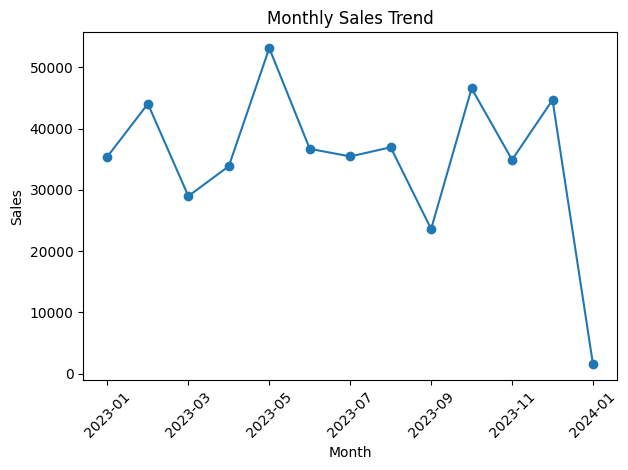

In [3]:
df = df.dropna(subset=["Date", "Total Amount"])

df["Month"] = df["Date"].dt.to_period("M").astype(str)

monthly_sales = df.groupby("Month")["Total Amount"].sum()

monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

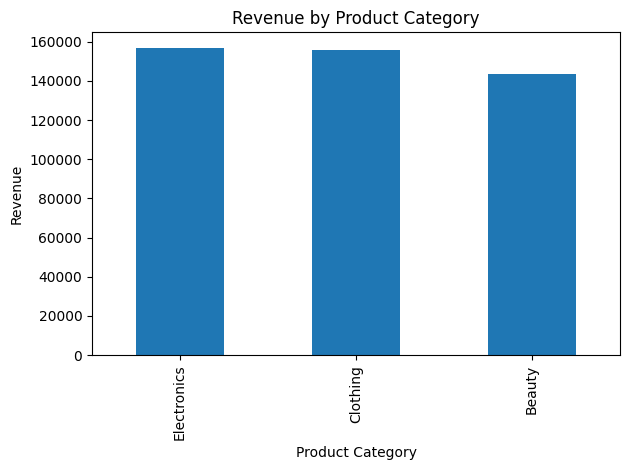

In [4]:
category_sales = df.groupby(
    "Product Category"
)["Total Amount"].sum().sort_values(ascending=False)

category_sales.plot(kind="bar")
plt.title("Revenue by Product Category")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

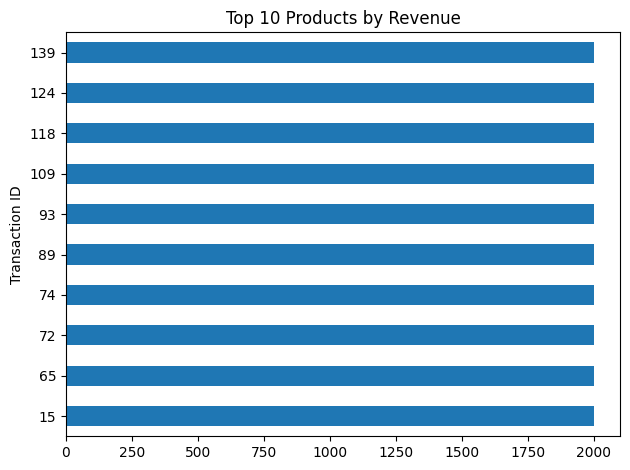

In [7]:
top_products = df.groupby(
    "Transaction ID"
)["Total Amount"].sum().nlargest(10)

top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.tight_layout()
plt.show()

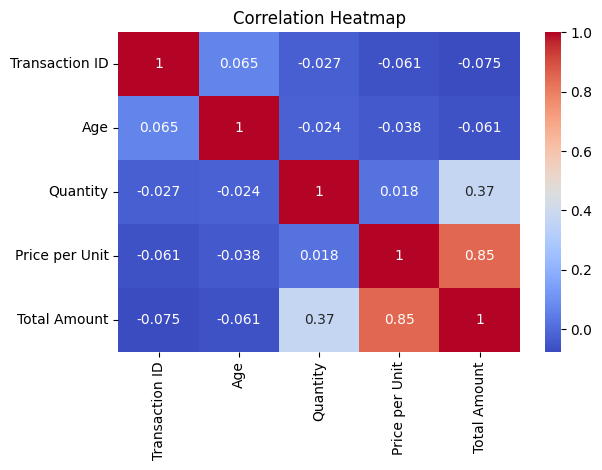

In [8]:
numeric = df.select_dtypes(include="number")

sns.heatmap(numeric.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()